# Stochastic calculus for an institutional equity investor
## From random price moves to portfolio decisions

Imagine you help manage a **100 million currency-unit equity portfolio**. Your team has a stock-selection process. You now need to ask: How much can we lose? Which holdings drive that risk? What does protection cost? How should a large trade be executed?

Stochastic models turn assumptions about uncertainty into distributions of outcomes. **They do not create a stock-selection edge by themselves.** In this lesson, every market input is synthetic and every result is conditional on the assumptions you choose. There are no live prices, estimated investment forecasts, or recommended trades.

**How to study:** read the question, predict the result, run the cell, then read the interpretation. Change one parameter at a time. Basic Python, averages, variance, and derivatives are enough to start; the advanced sections are optional.

**Run:** choose the project `.venv` / `ml-mac-mini` kernel and **Restart Kernel and Run All**. Only NumPy, SciPy, Matplotlib, and IPython are needed; they are already covered by the project environment. No GPU, credentials, downloads, or installation cells are required. Run from the top after editing an upstream assumption.

### Route through the notebook

1. [Brownian motion: how do we scale uncertainty?](#brownian)
2. [Itô calculus: why does volatility change compound growth?](#ito)
3. [Lévy jumps: what if prices gap?](#jumps)
4. [Portfolio risk: what happens when holdings move together?](#portfolio)
5. [Equity protection: scenarios under P, prices under Q](#hedging)
6. [Malliavin calculus: sensitivities for a discontinuous payoff](#malliavin)
7. [Execution: how quickly should we trade?](#execution)
8. [SPDEs: modeling an entire liquidity curve](#spde)
9. [Turning a teaching model into an investment workflow](#workflow)

For a first pass as a portfolio manager, prioritize **1–5 and 7**. Sections 6 and 8 explain specialist methods; they are not prerequisites for building a useful risk tool.

### Read the symbols before the equations

- $S_t$: a stock or index level at time $t$; $V_t$: the portfolio value.
- $\mu$: assumed annual arithmetic return drift; $\sigma$: annual volatility. A drift is an input, not automatically alpha relative to a benchmark.
- $dt$: a short time interval in years. Here, one trading day is $1/252$ years.
- $W_t$: Brownian motion; $dW$: a new random shock. $Z\sim N(0,1)$ means a standard normal draw.
- $\mathbb E[X]$: the mean over possible outcomes; $\operatorname{Var}(X)$: their dispersion.
- A **path** is one simulated future. A **Monte Carlo estimate** averages many independent simulated futures.
- One **basis point (bp)** is $0.01\%$. A 100 bp loss on 100 million is 1 million.

Keep three errors separate: **sampling error** (too few simulations), **numerical error** (an approximate time step), and **model error** (the assumed world is wrong). Increasing the path count only addresses the first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm

plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "font.size": 10,
})
TRADING_DAYS = 252
PORTFOLIO_VALUE = 100_000_000.0
N_SCENARIOS = 80_000
SEED = 42


def mc_mean_se(samples):
    samples = np.asarray(samples)
    return samples.mean(), samples.std(ddof=1) / np.sqrt(samples.size)


def loss_risk(pnl, confidence=0.975):
    """Positive numbers mean losses; ES averages the empirical tail beyond VaR."""
    losses = -np.asarray(pnl)
    var = np.quantile(losses, confidence)
    tail = losses >= var
    return var, losses[tail].mean(), tail


print(f"Synthetic portfolio: {PORTFOLIO_VALUE / 1e6:.0f} million currency units")
print(f"Scenarios per experiment: {N_SCENARIOS:,}; CPU-only; fixed seeds")

Synthetic portfolio: 100 million currency units
Scenarios per experiment: 80,000; CPU-only; fixed seeds


<a id="brownian"></a>
## 1. Brownian motion: uncertainty grows with the square root of time

**Desk question:** if annual volatility is 20%, what is a typical one-day move?

We model a small return as
$$\frac{\Delta S}{S}\approx\mu\,\Delta t+\sigma\sqrt{\Delta t}\,Z.$$
The drift scales with time; the standard deviation scales with its square root. With 8% drift and 20% volatility, daily drift is about 0.032%, while daily standard deviation is about 1.26%. Noise dominates the daily observation.

Brownian motion has continuous paths and independent normal increments, with $\operatorname{Var}(\Delta W)=\Delta t$. This is a convenient baseline. It omits gaps, changing volatility, and dependence between successive returns.

**Predict:** if you split one year into more steps, do the squared increments add up to zero? We use nested grids on the **same paths** to investigate.

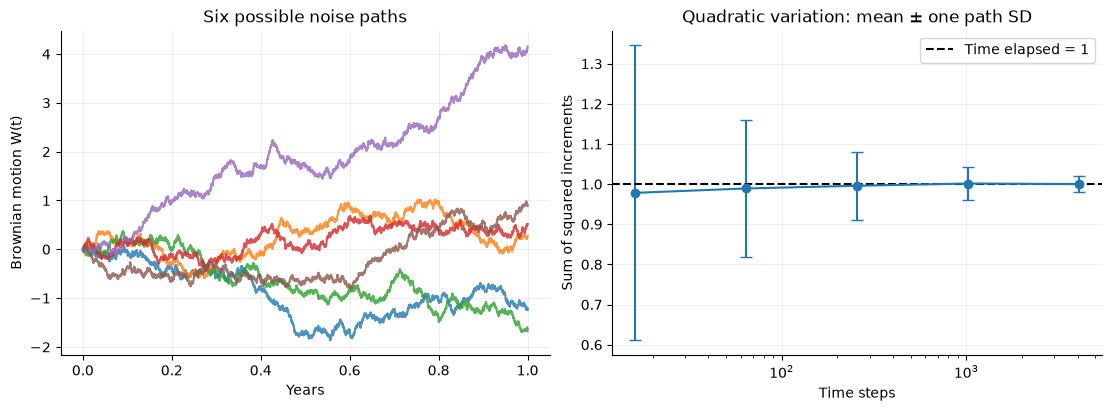

Daily drift at 8% annual: 0.032%
Daily volatility at 20% annual: 1.26%
Finest-grid average quadratic variation: 1.0001


In [2]:
rng = np.random.default_rng(SEED)
n_fine, n_paths_bm = 4096, 400
fine_dW = rng.normal(size=(n_paths_bm, n_fine)) / np.sqrt(n_fine)
W = np.column_stack([np.zeros(n_paths_bm), np.cumsum(fine_dW, axis=1)])
mesh_sizes = np.array([16, 64, 256, 1024, 4096])
qv = np.stack([
    np.square(fine_dW.reshape(n_paths_bm, n, n_fine // n).sum(axis=2)).sum(axis=1)
    for n in mesh_sizes
])

fig, axes = plt.subplots(1, 2, layout="constrained")
axes[0].plot(np.linspace(0, 1, n_fine + 1), W[:6].T, alpha=0.8)
axes[0].set(xlabel="Years", ylabel="Brownian motion W(t)", title="Six possible noise paths")
axes[1].errorbar(mesh_sizes, qv.mean(axis=1), yerr=qv.std(axis=1), fmt="o-", capsize=4)
axes[1].axhline(1, color="black", ls="--", label="Time elapsed = 1")
axes[1].set(xscale="log", xlabel="Time steps", ylabel="Sum of squared increments",
            title="Quadratic variation: mean ± one path SD")
axes[1].legend()
plt.show()
print(f"Daily drift at 8% annual: {0.08 / TRADING_DAYS:.3%}")
print(f"Daily volatility at 20% annual: {0.20 / np.sqrt(TRADING_DAYS):.2%}")
print(f"Finest-grid average quadratic variation: {qv[-1].mean():.4f}")

**Read the figure:** paths diverge, but the sum $\sum(\Delta W)^2$ concentrates around elapsed time. The usual shorthand $(dW)^2=dt$ describes this limiting quadratic variation; it is **not an equality for each random increment**.

**Try:** change the daily-volatility calculation from 20% to 40%. The daily standard deviation doubles; variance quadruples. Doubling the horizon multiplies standard deviation by $\sqrt{2}$ under this model. Scaling risk across time this way becomes unreliable when its independence and constant-volatility assumptions fail.

<a id="ito"></a>
## 2. Itô calculus: the chain rule remembers squared noise

For an SDE $dX=a\,dt+b\,dW$ and a smooth function $f(t,X)$, the stochastic chain rule is
$$df=\left(f_t+a f_x+\tfrac12 b^2 f_{xx}\right)dt+b f_x\,dW.$$
Here $f_t$ and $f_x$ are derivatives with respect to time and the state, and $f_{xx}$ is curvature with respect to the state. The extra second-derivative term comes from the squared increments above. Think of it as **curvature interacting with uncertainty**.

Take $f(W)=W^2$. Itô's formula gives
$$\int_0^T W_t\,dW_t=\tfrac12(W_T^2-T).$$
An Itô sum uses the value known **before** the next shock. A Stratonovich sum uses midpoints and gives $\int W\circ dW=\tfrac12 W_T^2$. For a financial trading strategy, choosing holdings before the next price change is the natural convention.

**These conventions require different drifts for the same process.** For example, the Itô equation $dS=\mu Sdt+\sigma S dW$ corresponds to the Stratonovich equation $dS=(\mu-\sigma^2/2)Sdt+\sigma S\circ dW$. Switching the integral convention while keeping the drift changes the model.

In [3]:
left_sum = np.sum(W[:, :-1] * fine_dW, axis=1)
midpoint_sum = np.sum(0.5 * (W[:, :-1] + W[:, 1:]) * fine_dW, axis=1)
ito_limit = 0.5 * (W[:, -1]**2 - 1)
strat_limit = 0.5 * W[:, -1]**2
print(f"Itô approximation, first path: {left_sum[0]:.4f}; limiting expression: {ito_limit[0]:.4f}")
print(f"Midpoint sum, first path:       {midpoint_sum[0]:.4f}; expression: {strat_limit[0]:.4f}")
print(f"Average midpoint-minus-left:    {(midpoint_sum - left_sum).mean():.4f} (target: 0.5)")

Itô approximation, first path: 0.2716; limiting expression: 0.2692
Midpoint sum, first path:       0.7692; expression: 0.7692
Average midpoint-minus-left:    0.5001 (target: 0.5)


### Apply the chain rule to an equity price

Use geometric Brownian motion (GBM): $dS/S=\mu\,dt+\sigma\,dW$, with constant parameters and no dividends. Setting $f(S)=\log S$ gives $f'=1/S$ and $f''=-1/S^2$, so
$$d\log S=(\mu-\tfrac12\sigma^2)dt+\sigma dW,$$
$$S_T=S_0\exp[(\mu-\tfrac12\sigma^2)T+\sigma W_T].$$

Consequently, $\mathbb E[S_T]=S_0e^{\mu T}$, while the median is $S_0e^{(\mu-\sigma^2/2)T}$. Holding arithmetic drift fixed, more volatility lowers typical compound growth, **not this model's expected terminal price**.

**Desk use:** generate conditional valuation/risk scenarios; understand why an expected return and a typical compound return are different. GBM does not estimate a company's fair value or identify which stock will outperform.

The exponential update below is exact at the observation times for constant-parameter GBM. Euler–Maruyama is the simpler approximate update $S_{t+dt}=S_t(1+\mu dt+\sigma\Delta W)$; unlike the exact update, it can become negative at large steps.

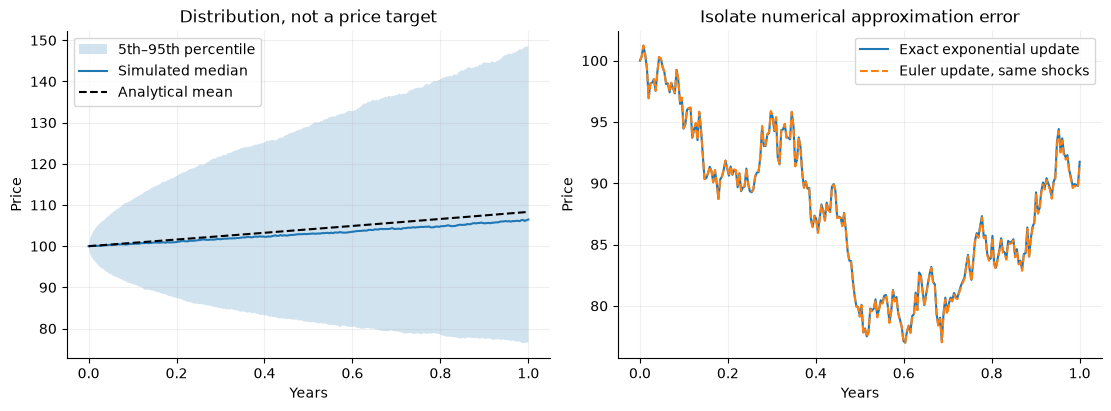

Terminal mean: simulated 108.37 ± 0.56 (approx. 95% MC interval)
Analytical mean: 108.33; median: 106.18


In [4]:
# Experiment controls: annual arithmetic drift and volatility; time is in years.
S0, MU, SIGMA, T_GBM = 100.0, 0.08, 0.20, 1.0
N_STEPS_GBM, N_PATHS_GBM = 252, 6000
rng = np.random.default_rng(SEED + 1)
dt_gbm = T_GBM / N_STEPS_GBM
dW_gbm = rng.normal(size=(N_PATHS_GBM, N_STEPS_GBM)) * np.sqrt(dt_gbm)
log_steps = (MU - 0.5 * SIGMA**2) * dt_gbm + SIGMA * dW_gbm
gbm_paths = S0 * np.exp(np.column_stack([np.zeros(N_PATHS_GBM), np.cumsum(log_steps, axis=1)]))
time_gbm = np.linspace(0, T_GBM, N_STEPS_GBM + 1)
q05, q50, q95 = np.quantile(gbm_paths, [0.05, 0.5, 0.95], axis=0)
euler_path = S0 * np.r_[1.0, np.cumprod(1 + MU * dt_gbm + SIGMA * dW_gbm[0])]

fig, axes = plt.subplots(1, 2, layout="constrained")
axes[0].fill_between(time_gbm, q05, q95, alpha=0.2, label="5th–95th percentile")
axes[0].plot(time_gbm, q50, label="Simulated median")
axes[0].plot(time_gbm, S0 * np.exp(MU * time_gbm), "k--", label="Analytical mean")
axes[0].set(xlabel="Years", ylabel="Price", title="Distribution, not a price target")
axes[0].legend()
axes[1].plot(time_gbm, gbm_paths[0], label="Exact exponential update")
axes[1].plot(time_gbm, euler_path, "--", label="Euler update, same shocks")
axes[1].set(xlabel="Years", ylabel="Price", title="Isolate numerical approximation error")
axes[1].legend()
plt.show()
gbm_mean, gbm_se = mc_mean_se(gbm_paths[:, -1])
print(f"Terminal mean: simulated {gbm_mean:.2f} ± {1.96 * gbm_se:.2f} (approx. 95% MC interval)")
print(f"Analytical mean: {S0 * np.exp(MU*T_GBM):.2f}; median: {S0 * np.exp((MU-SIGMA**2/2)*T_GBM):.2f}")

**Interpretation:** the shaded band is a pointwise outcome range under our assumptions, not a confidence interval for an estimated fair value. It is also not a band that contains 90% of entire paths. The printed Monte Carlo interval concerns the estimated mean only.

**Try:** set `SIGMA = 0.40` and rerun from this cell. Before running, calculate $\mu-\sigma^2/2$. At 8% drift and 40% volatility, it is zero: the median terminal price stays at its initial level after a year, even though the mean rises.

For more on stochastic integration, see the [MIT lecture on Itô calculus](https://ocw.mit.edu/courses/18-s096-topics-in-mathematics-with-applications-in-finance-fall-2013/93ea3f1f17548c6c8933bd5cea2a17e0_Z5yRMMVUC5w.pdf).

<a id="jumps"></a>
## 3. Lévy processes: distinguish ordinary noise from price gaps

**Desk question:** does a volatility number adequately describe a concentrated holding's loss risk?

A Lévy process has stationary independent increments (with the usual continuity-in-probability condition). Brownian motion and compound Poisson jumps are building blocks. With constant parameters, the **log price** in the following model is Lévy; the price itself generally is not.

Let $N_T\sim\operatorname{Poisson}(\lambda T)$ count jumps, and let each log jump $Y_j\sim N(m_J,s_J^2)$. A jump multiplies price by $e^{Y_j}$, so a log jump of $-0.15$ is a simple return of about $-13.9\%$.

We use a compensated jump model:
$$\log(S_T/S_0)=(\mu-\lambda\kappa-\tfrac12\sigma_D^2)T+\sigma_D\sqrt T Z+\sum_{j=1}^{N_T}Y_j,$$
$$\kappa=\mathbb E[e^Y-1]=e^{m_J+s_J^2/2}-1.$$
Subtracting $\lambda\kappa$ keeps the arithmetic expected growth at $\mu$: $\mathbb E[S_T]=S_0e^{\mu T}$. Without it, changing jump assumptions also changes that mean.

We compare with GBM using **equal expected price growth and equal log-return variance**:
$$\sigma_{GBM}^2=\sigma_D^2+\lambda(s_J^2+m_J^2).$$
This does not match every return statistic. It makes the tail comparison more informative than simply adding more variance to one model.

The model follows the diffusion-plus-jump construction in [Merton's jump-diffusion paper](https://dspace.mit.edu/entities/publication/e63635d9-d2bf-40ce-a79b-67786dd9f105). Our comparison is a synthetic risk experiment, not a calibration of that paper's option-pricing model.

GBM: P(return < -15%) = 1.08% ± 0.07%; 97.5% VaR = 12.95m, ES = 15.25m
Jump model: P(return < -15%) = 3.46% ± 0.13%; 97.5% VaR = 17.82m, ES = 23.99m


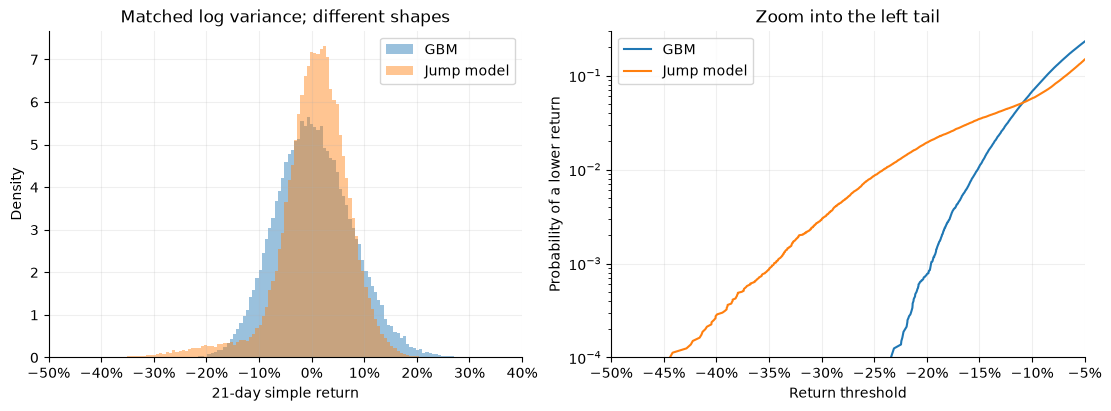

In [5]:
def jump_log_return(mu, sigma_diffusion, intensity, jump_mean, jump_sd, horizon, size, seed):
    """Exact terminal log-return draws for independent normal compound-Poisson jumps."""
    if horizon <= 0 or min(sigma_diffusion, intensity, jump_sd) < 0:
        raise ValueError("Require a positive horizon and nonnegative volatility/intensity.")
    rng = np.random.default_rng(seed)
    z_diffusion = rng.normal(size=size)
    counts = rng.poisson(intensity * horizon, size=size)
    # Conditional on n, the sum of n independent Gaussian jumps is Gaussian.
    jump_sum = counts * jump_mean + np.sqrt(counts) * jump_sd * rng.normal(size=size)
    kappa = np.expm1(jump_mean + 0.5 * jump_sd**2)
    return ((mu - intensity * kappa - 0.5 * sigma_diffusion**2) * horizon
            + sigma_diffusion * np.sqrt(horizon) * z_diffusion + jump_sum)


JUMP_MU, JUMP_SD, JUMP_INTENSITY = -0.15, 0.10, 1.0
TOTAL_LOG_VOL, JUMP_HORIZON, JUMP_DRIFT = 0.25, 21 / TRADING_DAYS, 0.06
jump_variance = JUMP_INTENSITY * (JUMP_SD**2 + JUMP_MU**2)
if jump_variance > TOTAL_LOG_VOL**2:
    raise ValueError("Jump variance exceeds the total variance budget; change assumptions.")
DIFFUSION_VOL = np.sqrt(TOTAL_LOG_VOL**2 - jump_variance)
rng = np.random.default_rng(SEED + 2)
normal_returns = np.expm1((JUMP_DRIFT - TOTAL_LOG_VOL**2 / 2) * JUMP_HORIZON
                        + TOTAL_LOG_VOL * np.sqrt(JUMP_HORIZON) * rng.normal(size=N_SCENARIOS))
jump_returns = np.expm1(jump_log_return(
    JUMP_DRIFT, DIFFUSION_VOL, JUMP_INTENSITY, JUMP_MU, JUMP_SD,
    JUMP_HORIZON, N_SCENARIOS, SEED + 3))

shared_bins = np.histogram_bin_edges(np.r_[normal_returns, jump_returns], bins=150)
fig, axes = plt.subplots(1, 2, layout="constrained")
for name, returns in [("GBM", normal_returns), ("Jump model", jump_returns)]:
    axes[0].hist(returns, bins=shared_bins, density=True, alpha=0.45, label=name)
    sorted_returns = np.sort(returns)
    axes[1].plot(sorted_returns, np.arange(1, returns.size + 1) / returns.size, label=name)
    var, es, _ = loss_risk(PORTFOLIO_VALUE * returns)
    probability = np.mean(returns < -0.15)
    probability_se = np.sqrt(probability * (1 - probability) / returns.size)
    print(f"{name}: P(return < -15%) = {probability:.2%} ± {1.96 * probability_se:.2%}; "
          f"97.5% VaR = {var/1e6:.2f}m, ES = {es/1e6:.2f}m")
axes[0].set(xlim=(-0.5, 0.4), xlabel="21-day simple return", ylabel="Density", title="Matched log variance; different shapes")
axes[1].set(xlim=(-0.5, -0.05), ylim=(0.0001, 0.3), yscale="log",
            xlabel="Return threshold", ylabel="Probability of a lower return", title="Zoom into the left tail")
for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.legend()
plt.show()

**Read the left tail:** equal log variance does not imply equal crash probabilities or equal expected tail losses. The reported probability intervals measure simulation noise, not uncertainty about jump parameters. We define VaR and ES carefully in the next section.

**Institutional uses:** compare issuer gap scenarios, challenge a volatility-only position limit, or test the residual exposure after a hedge. This model does not make jumps predictable.

**Important modeling choice:** a homogeneous Poisson model describes randomly timed events. A scheduled earnings release calls for an explicit event-date jump distribution; forcing earnings into a constant arrival intensity hides information you already have. A constant-parameter Lévy model also lacks volatility clustering and changing regimes.

**Try:** set `JUMP_INTENSITY = 0`. The two distributions should become statistically similar. Increasing intensity while keeping the same total variance requires reducing diffusion volatility; the code rejects impossible variance budgets.

<a id="portfolio"></a>
## 4. From stock paths to portfolio and benchmark risk

**Desk question:** which exposures should the risk committee discuss, and how fragile is diversification?

We create six synthetic sector sleeves. The baseline covariance comes from a market factor plus independent residual risk:
$$\Sigma=\sigma_M^2\beta\beta^\top+\operatorname{diag}(\sigma_{\epsilon,i}^2).$$
$\beta_i$ is sensitivity to the market factor. A Cholesky factor $L$, with $LL^\top=\Sigma$, turns independent normals into correlated shocks: $\sqrt T\,ZL^\top$ in our row-oriented NumPy code.

With initial weights $w$ and stock simple returns $R$, a **buy-and-hold** portfolio's horizon P&L is $V_0\sum_iw_iR_i$. Benchmark weights $b$ give active weights $a=w-b$. The familiar local annual tracking-error approximation is $\sqrt{a^\top\Sigma a}$; simulated multi-day active returns need not match that approximation exactly.

We compare three worlds using the same independent draws:

1. Baseline factor covariance.
2. 85% pairwise correlation, with each sleeve's marginal volatility unchanged.
3. The high-correlation world plus a **specified** market log-price gap of $-0.12$, scaled by each sleeve's beta.

The third is a conditional stress scenario, not an event probability or a forecast. Its mean differs deliberately.

### Two tail measures, one sign convention

We define loss as $L=-\mathrm{P\&L}$. **97.5% VaR** is the loss threshold exceeded in roughly 2.5% of scenarios. **Expected shortfall (ES)** is the average loss in that worst tail (our continuous-sample estimate averages observations beyond VaR). VaR is not the maximum possible loss. Neither statistic here measures a path's peak-to-trough drawdown.

Baseline: VaR 9.66m; ES 11.52m; 21-day active-return SD 0.72%
High correlation: VaR 12.01m; ES 14.28m; 21-day active-return SD 0.47%
Correlation + gap: VaR 22.32m; ES 24.30m; 21-day active-return SD 0.38%
Baseline local annual tracking-error approximation: 2.47%


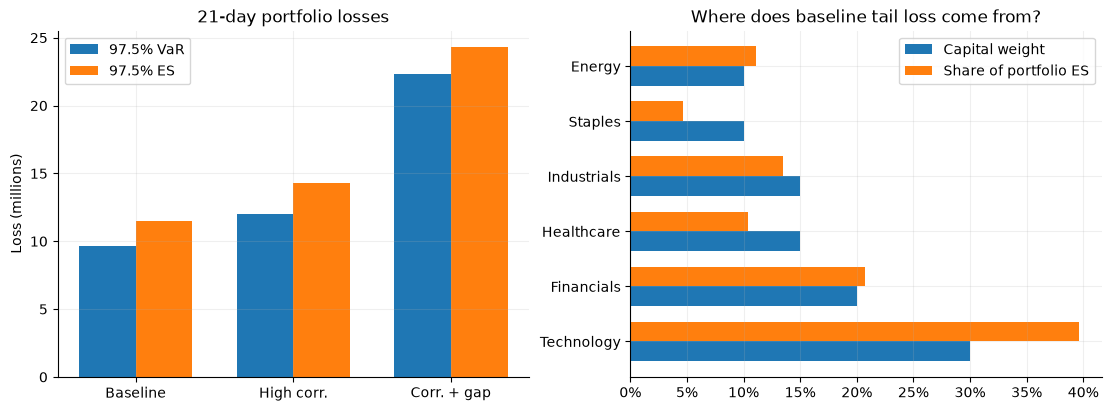

In [6]:
# Synthetic sleeves, initial portfolio weights, and a synthetic benchmark.
sector_names = np.array(["Technology", "Financials", "Healthcare", "Industrials", "Staples", "Energy"])
weights = np.array([0.30, 0.20, 0.15, 0.15, 0.10, 0.10])
benchmark = np.array([0.20, 0.20, 0.20, 0.15, 0.15, 0.10])
betas = np.array([1.30, 1.10, 0.75, 1.00, 0.55, 1.20])
residual_vol = np.array([0.20, 0.18, 0.16, 0.17, 0.12, 0.25])
market_vol, portfolio_horizon = 0.16, 21 / TRADING_DAYS
sleeve_drift = np.full(6, 0.06)  # Equal drifts: this experiment supplies no stock-picking alpha.
STRESS_CORRELATION, MARKET_LOG_GAP = 0.85, -0.12

cov_base = market_vol**2 * np.outer(betas, betas) + np.diag(residual_vol**2)
vols = np.sqrt(np.diag(cov_base))
stress_corr = (1 - STRESS_CORRELATION) * np.eye(6) + STRESS_CORRELATION * np.ones((6, 6))
cov_stress = stress_corr * np.outer(vols, vols)
portfolio_z = np.random.default_rng(SEED + 4).normal(size=(N_SCENARIOS, 6))


def sleeve_returns(covariance, log_gap=0.0):
    L = np.linalg.cholesky(covariance)
    log_r = ((sleeve_drift - 0.5 * np.diag(covariance)) * portfolio_horizon
             + np.sqrt(portfolio_horizon) * (portfolio_z @ L.T)
             + betas * log_gap)
    return np.expm1(log_r)


portfolio_scenarios = {
    "Baseline": sleeve_returns(cov_base),
    "High correlation": sleeve_returns(cov_stress),
    "Correlation + gap": sleeve_returns(cov_stress, MARKET_LOG_GAP),
}
portfolio_risks, portfolio_pnls = {}, {}
for name, returns in portfolio_scenarios.items():
    pnl = PORTFOLIO_VALUE * (returns @ weights)
    portfolio_pnls[name] = pnl
    var, es, tail = loss_risk(pnl)
    portfolio_risks[name] = (var, es)
    active_returns = returns @ (weights - benchmark)
    print(f"{name}: VaR {var/1e6:.2f}m; ES {es/1e6:.2f}m; "
          f"21-day active-return SD {active_returns.std(ddof=1):.2%}")

active_weights = weights - benchmark
tracking_error = np.sqrt(active_weights @ cov_base @ active_weights)
print(f"Baseline local annual tracking-error approximation: {tracking_error:.2%}")

fig, axes = plt.subplots(1, 2, layout="constrained")
positions = np.arange(len(portfolio_risks))
risk_values = np.array(list(portfolio_risks.values())) / 1e6
axes[0].bar(positions - 0.18, risk_values[:, 0], width=0.36, label="97.5% VaR")
axes[0].bar(positions + 0.18, risk_values[:, 1], width=0.36, label="97.5% ES")
axes[0].set(xticks=positions, xticklabels=["Baseline", "High corr.", "Corr. + gap"],
            ylabel="Loss (millions)", title="21-day portfolio losses")
axes[0].legend()
base_var, base_es, base_tail = loss_risk(portfolio_pnls["Baseline"])
# Condition each sleeve's loss on the PORTFOLIO tail, not its own tail.
component_es = (-PORTFOLIO_VALUE * portfolio_scenarios["Baseline"] * weights)[base_tail].mean(axis=0)
y_positions = np.arange(len(weights))
axes[1].barh(y_positions - 0.18, weights, height=0.36, label="Capital weight")
axes[1].barh(y_positions + 0.18, component_es / base_es, height=0.36, label="Share of portfolio ES")
axes[1].set(yticks=y_positions, yticklabels=sector_names, title="Where does baseline tail loss come from?")
axes[1].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[1].legend()
plt.show()

**Interpretation:** concentration can look larger in tail-risk contribution than in capital weight. The contributions sum to portfolio ES because they average each sleeve's loss over the same portfolio-tail observations. They are not standalone sleeve ES figures, and they are not the marginal effect of selling a position. A genuinely diversifying sleeve can have a negative contribution.

**Notice the distinction:** higher correlation can increase absolute portfolio risk while decreasing active-return dispersion. Common moves cancel in a portfolio-minus-benchmark comparison more than they cancel in the outright portfolio. Read both measures before judging a scenario.

**Action supported:** prepare a comparison of the existing portfolio and a proposed weight change. Discuss both absolute loss and benchmark-relative risk. This experiment does not optimize weights or account for the investment merits of the holdings.

**Try:** move 10 percentage points from Technology to Staples while keeping weights summing to one. Compare ES and tracking error. Then set `weights = benchmark.copy()`: active returns must be zero, but the portfolio still has market risk.

**Data needed:** point-in-time holdings and benchmark weights, correctly adjusted returns, consistent currencies, factor exposures, and residual covariance estimates. A foreign-equity mandate also needs FX exposures and hedges. Validate a covariance model on subsequent data and across stress periods; an attractive in-sample fit is insufficient.

<a id="hedging"></a>
## 5. Pricing protection and forecasting losses are different questions

**Desk question:** what does a protective put cost, and what happens to portfolio losses after paying for it?

A put pays $(K-S_T)^+=\max(K-S_T,0)$ at expiry. It offsets downside below strike $K$, but its premium must be funded.

**Physical measure $P$** represents assumed real-world outcomes: useful for loss probabilities and investment scenarios. **Risk-neutral measure $Q$** is the pricing measure in the model: here the stock's drift is $r-q$, where $r$ is the risk-free rate and $q$ the dividend yield. Discount the expected payoff under $Q$ to price it. Risk neutrality is not an assertion that actual investors expect stocks to earn the risk-free rate. See [MIT's risk-neutral valuation lecture](https://ocw.mit.edu/courses/18-642-topics-in-mathematics-with-applications-in-finance-fall-2024/mit18_642_f24_lec21.pdf).

For constant volatility, the European put formula is
$$P_0=Ke^{-rT}\Phi(-d_2)-S_0e^{-qT}\Phi(-d_1),$$
$$d_1=\frac{\log(S_0/K)+(r-q+\sigma^2/2)T}{\sigma\sqrt T},\qquad d_2=d_1-\sigma\sqrt T.$$
Here $\Phi$ is the standard normal cumulative distribution function. We verify the formula with a separate Monte Carlo estimate under $Q$, then evaluate outcomes under $P$.

In [7]:
def bs_put(spot, strike, maturity, rate, volatility, dividend_yield=0.0):
    if min(spot, strike, maturity, volatility) <= 0:
        raise ValueError("Spot, strike, maturity, and volatility must be positive.")
    d1 = (np.log(spot / strike) + (rate - dividend_yield + 0.5 * volatility**2) * maturity) / (volatility * np.sqrt(maturity))
    d2 = d1 - volatility * np.sqrt(maturity)
    return (strike * np.exp(-rate * maturity) * norm.cdf(-d2)
            - spot * np.exp(-dividend_yield * maturity) * norm.cdf(-d1))


HEDGE_SPOT, PUT_STRIKE, HEDGE_T = 100.0, 90.0, 0.25
HEDGE_VOL, RATE, PHYSICAL_DRIFT = 0.22, 0.03, 0.06
# No dividends in this example, so terminal stock-plus-put value needs no dividend cashflows.
put_premium = bs_put(HEDGE_SPOT, PUT_STRIKE, HEDGE_T, RATE, HEDGE_VOL)
q_z = np.random.default_rng(SEED + 5).normal(size=N_SCENARIOS)
terminal_q = HEDGE_SPOT * np.exp((RATE - 0.5 * HEDGE_VOL**2) * HEDGE_T + HEDGE_VOL * np.sqrt(HEDGE_T) * q_z)
put_mc, put_mc_se = mc_mean_se(np.exp(-RATE * HEDGE_T) * np.maximum(PUT_STRIKE - terminal_q, 0))
print(f"Put premium per underlying unit: formula {put_premium:.4f}; "
      f"Q Monte Carlo {put_mc:.4f} ± {1.96 * put_mc_se:.4f}")
print(f"Premium / spot: {put_premium / HEDGE_SPOT:.2%}")

Put premium per underlying unit: formula 0.8233; Q Monte Carlo 0.8147 ± 0.0169
Premium / spot: 0.82%


### Fund the hedge fairly

Start both strategies with the same wealth $V_0$. The unhedged strategy buys $V_0/S_0$ index units. The protected strategy buys $V_0/(S_0+P_0)$ packages, each containing **one index unit and one put**. It holds fewer index units because some cash pays the premium.

The protected strategy's terminal floor is therefore $V_0K/(S_0+P_0)$, rather than $V_0K/S_0$. All P&L below is measured against initial wealth; we do not include a cash-return opportunity-cost benchmark.

We use an exactly matching synthetic index as the portfolio proxy. An actual portfolio hedged with an index put retains **basis risk**: stock selection, sector tilts, currency, and changing beta can make it behave differently from the hedge underlying.

Unhedged: mean P&L 1.48m; 97.5% VaR 18.75m; ES 22.02m
Funded stock + put: mean P&L 1.39m; 97.5% VaR 10.73m; ES 10.73m
Protected expiry floor: 89.27% of initial wealth
Premium allocation: 0.82% of initial wealth


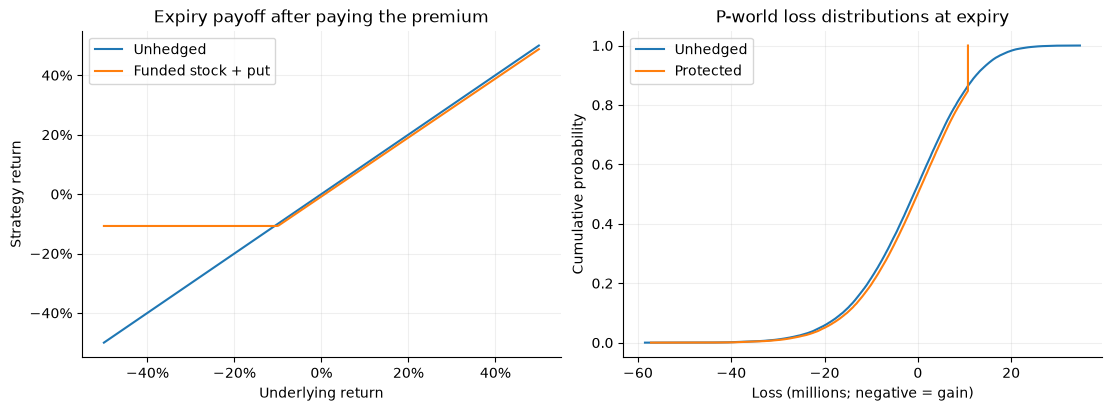

In [8]:
p_z = np.random.default_rng(SEED + 6).normal(size=N_SCENARIOS)
terminal_p = HEDGE_SPOT * np.exp((PHYSICAL_DRIFT - 0.5 * HEDGE_VOL**2) * HEDGE_T
                                + HEDGE_VOL * np.sqrt(HEDGE_T) * p_z)
stock_units = PORTFOLIO_VALUE / HEDGE_SPOT
protected_units = PORTFOLIO_VALUE / (HEDGE_SPOT + put_premium)
unhedged_pnl = stock_units * terminal_p - PORTFOLIO_VALUE
protected_pnl = protected_units * np.maximum(terminal_p, PUT_STRIKE) - PORTFOLIO_VALUE
protected_floor = protected_units * PUT_STRIKE

for name, pnl in [("Unhedged", unhedged_pnl), ("Funded stock + put", protected_pnl)]:
    var, es, _ = loss_risk(pnl)
    print(f"{name}: mean P&L {pnl.mean()/1e6:.2f}m; 97.5% VaR {var/1e6:.2f}m; ES {es/1e6:.2f}m")
print(f"Protected expiry floor: {protected_floor / PORTFOLIO_VALUE:.2%} of initial wealth")
print(f"Premium allocation: {protected_units * put_premium / PORTFOLIO_VALUE:.2%} of initial wealth")

spot_grid = np.linspace(50, 150, 300)
fig, axes = plt.subplots(1, 2, layout="constrained")
axes[0].plot(spot_grid / HEDGE_SPOT - 1, stock_units * spot_grid / PORTFOLIO_VALUE - 1, label="Unhedged")
axes[0].plot(spot_grid / HEDGE_SPOT - 1, protected_units * np.maximum(spot_grid, PUT_STRIKE) / PORTFOLIO_VALUE - 1,
             label="Funded stock + put")
axes[0].set(xlabel="Underlying return", ylabel="Strategy return", title="Expiry payoff after paying the premium")
axes[0].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].legend()
for label, pnl in [("Unhedged", unhedged_pnl), ("Protected", protected_pnl)]:
    ordered_losses = np.sort(-pnl / 1e6)
    axes[1].plot(ordered_losses, np.arange(1, N_SCENARIOS + 1) / N_SCENARIOS, label=label)
axes[1].set(xlabel="Loss (millions; negative = gain)", ylabel="Cumulative probability",
            title="P-world loss distributions at expiry")
axes[1].legend()
plt.show()

**Interpretation:** the put creates an expiry floor for the matching underlying. Paying for it reduces equity participation, including in rising markets. The model lets you compare strikes, expiry dates, premium budgets, and downside limits; a lower ES alone does not establish that a hedge is worth its cost.

**Try:** change `PUT_STRIKE` from 90 to 100. Predict the direction of the premium and the floor, then rerun the two cells. Change `PHYSICAL_DRIFT`: the assumed P-world outcomes change, while the formula premium does not. Changing the volatility used for pricing changes the premium.

**Before using market data:** distinguish forecast volatility under $P$ from option-implied volatility under $Q$. They are deliberately equal in this teaching example. Real implementation needs the volatility smile, dividends, rates, exercise style, contract multipliers, transaction costs, and portfolio-to-index mapping. Jump parameters under $P$ also cannot simply be reused under $Q$ without a pricing assumption. The floor is at expiry, not a guarantee on intermediate mark-to-market drawdowns.

<a id="malliavin"></a>
## 6. Malliavin calculus: differentiate with respect to the noise

**Desk question:** how can an equity derivatives team estimate a hedge sensitivity when a payoff has a sharp trigger?

Ordinary delta asks how value changes with today's spot $S_0$. The Malliavin derivative asks how a random output changes when the underlying Brownian noise is perturbed. For GBM,
$$D_s S_T=\sigma S_T\,\mathbf 1_{0\le s\le T}.$$
This is different from the spot sensitivity $\partial S_T/\partial S_0=S_T/S_0$. Differentiating an arbitrary array of random numbers with autograd does not, by itself, implement continuous-path Malliavin calculus.

Consider a European cash digital paying $A\mathbf 1_{S_T>K}$. For almost every simulated path, a tiny spot bump leaves that indicator unchanged. Its naive pathwise derivative is zero, yet the **expected** payoff changes because some probability mass crosses the strike.

Malliavin integration by parts can transfer differentiation from a nonsmooth payoff to a random weight. This is the financial application developed by [Fournié and coauthors](https://link.springer.com/article/10.1007/s007800050068).

### A concrete identity we can check

For terminal GBM with $Z\sim N(0,1)$, the lognormal likelihood-ratio (score) calculation gives
$$\Delta=e^{-rT}\mathbb E_Q\!\left[A\mathbf 1_{S_T>K}\frac{Z}{S_0\sigma\sqrt T}\right].$$
Indeed, differentiating the lognormal log density with respect to $S_0$ gives $Z/(S_0\sigma\sqrt T)$. In this simple terminal-payoff setting, this equals a Malliavin-weight representation; it is **not a general-purpose Malliavin solver**.

We compare it with common-random-number finite differences and the analytical delta $Ae^{-rT}\phi(d_2)/(S_0\sigma\sqrt T)$, with no dividends. $\phi$ is the standard normal density.

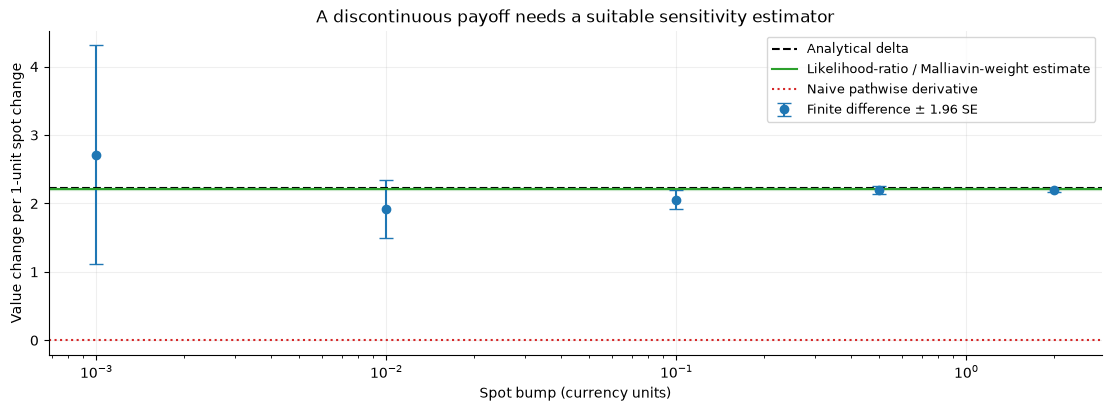

Analytical delta: 2.2231; weighted estimate: 2.2143 ± 0.0142
Bump 0.001: 11 paths crossed the strike out of 200,000
Bump 0.01: 78 paths crossed the strike out of 200,000
Bump 0.1: 835 paths crossed the strike out of 200,000
Bump 0.5: 4,461 paths crossed the strike out of 200,000
Bump 2: 17,872 paths crossed the strike out of 200,000


In [9]:
DIGITAL_SPOT, DIGITAL_STRIKE, DIGITAL_T = 100.0, 100.0, 0.5
DIGITAL_VOL, DIGITAL_RATE, DIGITAL_PAYOUT = 0.25, 0.03, 100.0
DIGITAL_N = 200_000
z_digital = np.random.default_rng(SEED + 7).normal(size=DIGITAL_N)
growth_digital = np.exp((DIGITAL_RATE - 0.5 * DIGITAL_VOL**2) * DIGITAL_T
                       + DIGITAL_VOL * np.sqrt(DIGITAL_T) * z_digital)
terminal_digital = DIGITAL_SPOT * growth_digital
discount_digital = np.exp(-DIGITAL_RATE * DIGITAL_T)
d2_digital = (np.log(DIGITAL_SPOT / DIGITAL_STRIKE)
              + (DIGITAL_RATE - 0.5 * DIGITAL_VOL**2) * DIGITAL_T) / (DIGITAL_VOL * np.sqrt(DIGITAL_T))
exact_digital_delta = DIGITAL_PAYOUT * discount_digital * norm.pdf(d2_digital) / (DIGITAL_SPOT * DIGITAL_VOL * np.sqrt(DIGITAL_T))
weighted_delta_samples = (discount_digital * DIGITAL_PAYOUT * (terminal_digital > DIGITAL_STRIKE)
                          * z_digital / (DIGITAL_SPOT * DIGITAL_VOL * np.sqrt(DIGITAL_T)))
weighted_delta, weighted_se = mc_mean_se(weighted_delta_samples)

bumps = np.array([0.001, 0.01, 0.1, 0.5, 2.0])
fd_means, fd_ses, crossing_counts = [], [], []
for bump in bumps:
    up = DIGITAL_PAYOUT * ((DIGITAL_SPOT + bump) * growth_digital > DIGITAL_STRIKE)
    down = DIGITAL_PAYOUT * ((DIGITAL_SPOT - bump) * growth_digital > DIGITAL_STRIKE)
    samples = discount_digital * (up - down) / (2 * bump)
    mean, se = mc_mean_se(samples)
    fd_means.append(mean)
    fd_ses.append(se)
    crossing_counts.append(np.count_nonzero(up != down))

fig, ax = plt.subplots(layout="constrained")
ax.errorbar(bumps, fd_means, yerr=1.96 * np.array(fd_ses), fmt="o", capsize=5,
            label="Finite difference ± 1.96 SE")
ax.axhline(exact_digital_delta, color="black", ls="--", label="Analytical delta")
ax.axhline(weighted_delta, color="tab:green", label="Likelihood-ratio / Malliavin-weight estimate")
ax.axhspan(weighted_delta - 1.96 * weighted_se, weighted_delta + 1.96 * weighted_se,
           color="tab:green", alpha=0.15)
ax.axhline(0, color="tab:red", ls=":", label="Naive pathwise derivative")
ax.set(xscale="log", xlabel="Spot bump (currency units)", ylabel="Value change per 1-unit spot change",
       title="A discontinuous payoff needs a suitable sensitivity estimator")
ax.legend(fontsize=9)
plt.show()
print(f"Analytical delta: {exact_digital_delta:.4f}; weighted estimate: {weighted_delta:.4f} ± {1.96 * weighted_se:.4f}")
for bump, count in zip(bumps, crossing_counts):
    print(f"Bump {bump:g}: {count:,} paths crossed the strike out of {DIGITAL_N:,}")

**Interpretation:** a smaller finite-difference bump does not automatically produce a better estimate. Very few paths may cross the strike, creating high variance; large bumps introduce bias. The plotted error bars cover sampling error around each estimator's mean, not finite-difference bias. With few crossings, normal confidence intervals are also unreliable.

The weighted estimator handles this particular discontinuity without selecting a bump. It is not universally the lowest-variance estimator: short maturities, rare payoffs, and more complex models can still create substantial variance.

**Institutional use:** a specialist team valuing digital, barrier, or structured equity exposures may need such sensitivity methods. A cash-equity PM would usually consume the resulting risk numbers rather than implement this calculus. Barrier and path-dependent claims require their own valid estimator; do not reuse this terminal digital formula blindly.

**Try:** increase `DIGITAL_STRIKE` to 150 or shorten maturity to 0.02. Watch the number of relevant paths and uncertainty. If no payoff event appears in a finite sample, a reported zero estimate and zero sample SE do not prove zero true risk.

<a id="execution"></a>
## 7. Execution: the investment idea still has to be traded

**Desk question:** we need to sell one million shares; should we finish early or spread the order through the day?

Trading faster can increase impact; trading slower leaves inventory exposed to price uncertainty. This trade-off motivates [Almgren and Chriss's optimal-execution framework](https://www.smallake.kr/wp-content/uploads/2016/03/optliq.pdf). Here we compare three prescribed schedules in a simplified model; we do not solve the full optimal-control problem.

Let $n_k$ be shares sold at the **start** of bucket $k$, $\Delta t$ its duration in days, and $x_{k+1}$ the shares remaining after that trade. Model unaffected price changes as $\Delta S_k=\sigma_{\$}\sqrt{\Delta t}Z_k$. With constant half-spread $h$ and linear temporary impact per share $\eta n_k/\Delta t$,
$$\text{cost}=hQ+\eta\sum_k n_k^2/\Delta t-\sum_kx_{k+1}\Delta S_k.$$
Cost is implementation shortfall relative to selling $Q$ shares at the arrival price: positive means worse proceeds. Thus
$$\mathbb E[\text{cost}]=hQ+\eta\sum_k n_k^2/\Delta t,\quad
\operatorname{SD}(\text{cost})=\sigma_{\$}\sqrt{\Delta t\sum_k x_{k+1}^2}.$$

This example has no alpha, permanent impact, variable liquidity, or market-volume curve. All trades fill immediately at the modeled price.

Even pace: expected cost 3.00 bp; cost SD 111.13 bp; simulated 95th-percentile cost 185.03 bp
Earlier: expected cost 3.62 bp; cost SD 82.99 bp; simulated 95th-percentile cost 139.76 bp
Much earlier: expected cost 6.98 bp; cost SD 49.16 bp; simulated 95th-percentile cost 86.69 bp


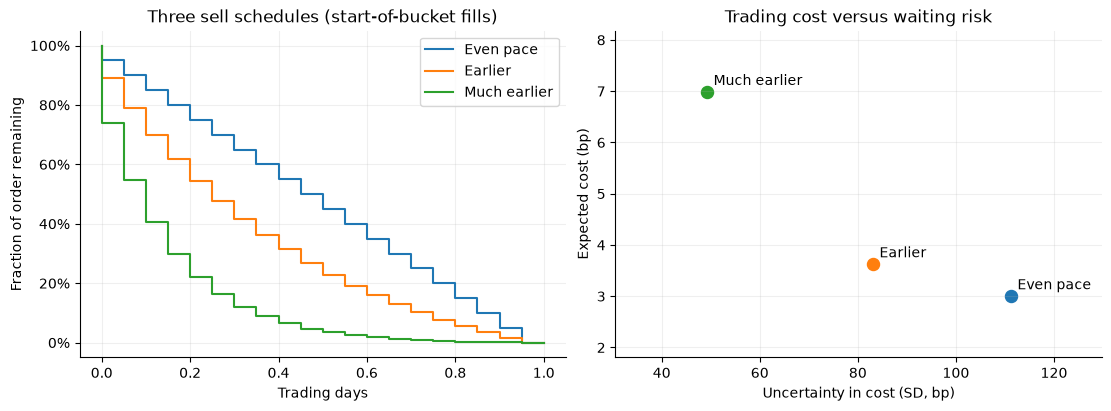

In [10]:
ORDER_SHARES, ARRIVAL_PRICE, ADV = 1_000_000.0, 50.0, 10_000_000.0
EXECUTION_DAYS, EXECUTION_BUCKETS = 1.0, 20
DAILY_PRICE_VOL, HALF_SPREAD = 1.0, 0.005  # Currency/share; daily volatility is 2% of 50.
ETA = 0.10 / ADV  # At a rate of one ADV/day, temporary impact = 0.10 currency/share.
bucket_times = np.linspace(0, EXECUTION_DAYS, EXECUTION_BUCKETS + 1)
dt_execution = EXECUTION_DAYS / EXECUTION_BUCKETS
execution_shocks = np.random.default_rng(SEED + 8).normal(size=(30_000, EXECUTION_BUCKETS))
execution_results = {}

fig, axes = plt.subplots(1, 2, layout="constrained")
for label, urgency in [("Even pace", 0.0), ("Earlier", 2.0), ("Much earlier", 6.0)]:
    fraction = bucket_times / EXECUTION_DAYS
    if urgency == 0:
        inventory = ORDER_SHARES * (1 - fraction)
    else:
        inventory = ORDER_SHARES * (np.exp(-urgency * fraction) - np.exp(-urgency)) / (1 - np.exp(-urgency))
    trades = -np.diff(inventory)
    remaining = inventory[1:]
    expected_cost = HALF_SPREAD * ORDER_SHARES + ETA * np.sum(trades**2) / dt_execution
    cost_sd = DAILY_PRICE_VOL * np.sqrt(dt_execution * np.sum(remaining**2))
    costs = expected_cost - DAILY_PRICE_VOL * np.sqrt(dt_execution) * (execution_shocks @ remaining)
    bp_scale = 10_000 / (ORDER_SHARES * ARRIVAL_PRICE)
    execution_results[label] = dict(inventory=inventory, trades=trades, costs=costs,
                                   expected_cost=expected_cost, cost_sd=cost_sd)
    axes[0].step(bucket_times, inventory / ORDER_SHARES, where="pre", label=label)
    axes[1].scatter(cost_sd * bp_scale, expected_cost * bp_scale, s=75)
    axes[1].annotate(label, (cost_sd * bp_scale, expected_cost * bp_scale), xytext=(5, 5), textcoords="offset points")
    print(f"{label}: expected cost {expected_cost * bp_scale:.2f} bp; cost SD {cost_sd * bp_scale:.2f} bp; "
          f"simulated 95th-percentile cost {np.quantile(costs, .95) * bp_scale:.2f} bp")
axes[0].set(xlabel="Trading days", ylabel="Fraction of order remaining", title="Three sell schedules (start-of-bucket fills)")
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].legend()
axes[1].set(xlabel="Uncertainty in cost (SD, bp)", ylabel="Expected cost (bp)", title="Trading cost versus waiting risk")
axes[1].margins(0.3)
plt.show()

**Interpretation:** front-loading reduces remaining-inventory price risk but increases the quadratic impact cost. No schedule wins on both criteria in this simplified comparison. Higher price volatility makes waiting more consequential; greater impact makes speed more expensive.

**Try:** double `ORDER_SHARES`. Holding schedules' fractional shapes fixed, impact cost grows fourfold in currency terms; price-risk SD grows twofold. This is why strategy capacity matters when moving from a small research portfolio to an institutional book.

**To implement:** estimate impact from the desk's own orders and market conditions; incorporate volume participation, spreads, venues, fill uncertainty, and execution constraints. Evaluate cost against a clearly chosen benchmark. A volume forecast and a credible impact estimate may add more practical value than a more elaborate price diffusion.

<a id="spde"></a>
## 8. SPDEs: a whole curve can be the state variable

An SDE evolves a finite set of quantities, such as six sleeve returns. An SPDE evolves a **random field** $u(t,x)$: one value at every location $x$, evolving through time. A limit-order-book depth curve is one possible equity-market application; [Cont and Mueller](https://arxiv.org/abs/1904.03058) study an SPDE model coupled to price dynamics.

**Our smaller teaching experiment:** $x\in[0,1]$ is normalized distance from a fixed reference price. $u$ is a **signed liquidity deviation** from a baseline, not actual nonnegative shares available to trade. A negative patch represents depletion. We show smoothing, replenishment, and random disturbances:
$$du=[\alpha u_{xx}-\kappa u]dt+\nu\,dW(t,x).$$
Here $\alpha$ smooths neighboring levels, $\kappa$ restores the baseline, and $\nu$ controls space-time white-noise intensity. Endpoints are fixed at zero deviation. This is an additive stochastic heat equation with mean reversion, **not an implementation of the cited order-book model**.

On a cell-averaged spatial grid, white-noise forcing scales as $\nu\sqrt{dt/dx}Z$. Using only $\sqrt{dt}$ gives a different grid-dependent noise model. We use an explicit finite-difference update with a conservative monotonicity condition $2\alpha dt/dx^2+\kappa dt\le1$.

**Predict:** if replenishment rises while the same noise is used, should the initial negative patch persist as long?

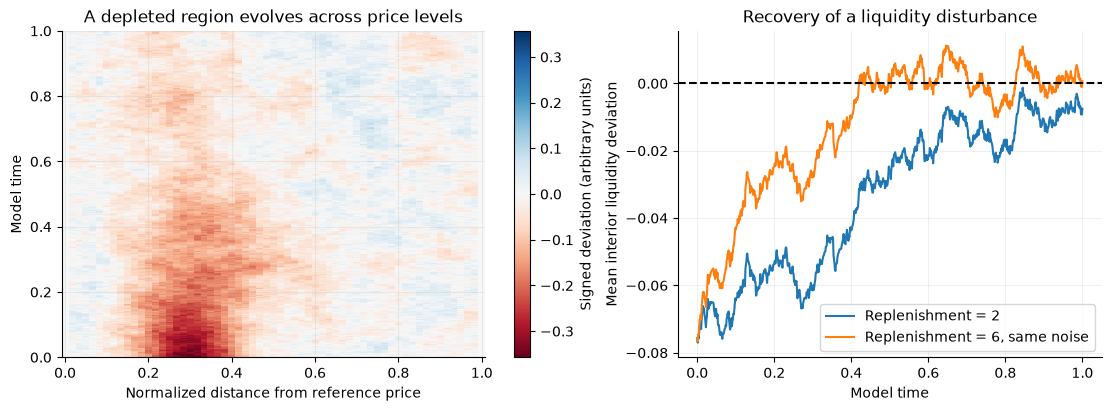

In [11]:
def simulate_liquidity_field(alpha=0.02, replenishment=2.0, noise=0.035,
                             nx=61, nt=800, horizon=1.0, seed=50):
    if nx < 3 or nt < 1 or horizon <= 0 or min(alpha, replenishment, noise) < 0:
        raise ValueError("Invalid grid, horizon, or coefficients.")
    x = np.linspace(0, 1, nx)
    t = np.linspace(0, horizon, nt + 1)
    dx, dt = x[1] - x[0], horizon / nt
    ratio = alpha * dt / dx**2
    if 2 * ratio + replenishment * dt > 1:
        raise ValueError("Increase nt: require 2*alpha*dt/dx**2 + replenishment*dt <= 1.")
    rng = np.random.default_rng(seed)
    u = np.zeros((nt + 1, nx))
    u[0, 1:-1] = -0.35 * np.exp(-((x[1:-1] - 0.3) / 0.12)**2)
    for step in range(nt):
        previous = u[step]
        lap = previous[2:] - 2 * previous[1:-1] + previous[:-2]
        u[step + 1, 1:-1] = ((1 - replenishment * dt) * previous[1:-1] + ratio * lap
                              + noise * np.sqrt(dt / dx) * rng.normal(size=nx - 2))
    return x, t, u


field_x, field_t, field = simulate_liquidity_field()
_, _, field_fast = simulate_liquidity_field(replenishment=6.0)
fig, axes = plt.subplots(1, 2, layout="constrained")
color_limit = np.max(np.abs(field))
mesh = axes[0].pcolormesh(field_x, field_t, field, shading="auto", cmap="RdBu",
                        vmin=-color_limit, vmax=color_limit)
fig.colorbar(mesh, ax=axes[0], label="Signed deviation (arbitrary units)")
axes[0].set(xlabel="Normalized distance from reference price", ylabel="Model time",
            title="A depleted region evolves across price levels")
axes[1].plot(field_t, field[:, 1:-1].mean(axis=1), label="Replenishment = 2")
axes[1].plot(field_t, field_fast[:, 1:-1].mean(axis=1), label="Replenishment = 6, same noise")
axes[1].axhline(0, color="black", ls="--")
axes[1].set(xlabel="Model time", ylabel="Mean interior liquidity deviation", title="Recovery of a liquidity disturbance")
axes[1].legend()
plt.show()

**Interpretation:** the heatmap displays one evolving spatial state, not a set of independent stock prices. Smoothing spreads a disturbance; mean reversion damps it; noise keeps creating new disturbances. The second panel uses identical random draws to compare replenishment assumptions.

**Potential desk use:** study the shape and recovery of liquidity across price levels, as an input to execution research. This toy field cannot tell you how many real shares will fill or what a trade will cost: it has arbitrary units, may be negative, and has no matching engine, queue position, reference-price motion, or impact coupling. A tradable-depth model must handle nonnegative depth and observed order flow.

**Try:** set `noise=0` to isolate deterministic recovery. Double `nx` without increasing `nt`: the stability check may reject the time step. Spatial refinement requires a smaller time step and a convergence study.

<a id="workflow"></a>
## 9. What would we actually build for an equity investment team?

The examples suggest a sequence of projects. The following prioritization is a practical inference from the experiments, not a claim about any particular institution's systems.

**First project — a portfolio scenario and sizing notebook.** Start with actual holdings, benchmark weights, currency exposures, and a chosen horizon. Compare current and proposed portfolios under historical shocks, a covariance model, and named issuer/sector/market stresses. Report loss distributions, tail contributions, and benchmark-relative risk. The decision is whether a position fits the risk budget, conditional on the investment thesis. Begin with transparent baselines before adding jumps or stochastic volatility.

**Second project — a hedge budget tool.** Map portfolio exposures to candidate index or single-name hedges; price actual contracts with market-consistent inputs. Compare premium budgets, basis risk, expiry losses, and intermediate liquidity requirements. The decision is which exposures to protect, by how much, and for how long. Pricing under $Q$ and outcome analysis under $P$ remain separate tasks.

**Third project — capacity and execution analysis.** Use intended order sizes, volume patterns, observed spreads, and the desk's fills to compare schedules and expected costs. The decision is whether an investment edge survives the cost of putting the position on and taking it off. SPDE research only becomes useful if the richer depth dynamics improve an observed trading outcome.

**For a derivatives research team — sensitivity infrastructure.** Compare analytical Greeks, finite differences, pathwise derivatives, likelihood-ratio weights, and suitable Malliavin methods. Choose an estimator for the actual payoff and model, and validate its bias, variance, and runtime. More sophisticated calculus is not automatically a better estimator.

### Replace toy inputs with evidence

1. **Define the decision first.** State the horizon, return convention, currency, benchmark, rebalancing rule, and loss measure. Terminal loss, drawdown, tracking error, and liquidation cost answer different questions.
2. **Prepare point-in-time data.** Use holdings known then; handle splits, dividends, delistings, stale prices, changing index membership, and currencies. Do not mix price returns and total returns unintentionally.
3. **Estimate and challenge inputs.** Separate return forecasts from risk estimates. Compare covariance windows or shrinkage; event-conditioned gap distributions; and volatility regimes. Pool sparse issuer events carefully. A handful of crashes cannot precisely identify a rich jump model.
4. **Hold out later periods.** Fit on a training period and evaluate on subsequent periods without hindsight. Compare quantiles, volatility, tail losses, and costs with simple historical or bootstrap baselines. Inspect clustered VaR exceptions as well as their count; backtest ES with an appropriate method alongside VaR.
5. **Turn outputs into net decisions.** Recalculate after proposed trades, including costs, cash, financing, restrictions, and hedge basis. A simulation does not establish causal alpha or profitable out-of-sample performance.
6. **Measure model uncertainty.** Rerun with alternate correlation, volatility, drift, event frequency, and liquidity assumptions. Keep numerical convergence tests separate from economic validation. More Monte Carlo paths do not rescue a wrong model.

### A capstone exercise

You propose increasing Technology from 30% to 40%, funded by reducing Staples from 10% to zero. Prepare a short investment-committee note:

- How much do baseline ES, stress ES, and tracking error change?
- Which changed number is relevant to the mandate's actual constraint?
- Would an index put address the added issuer/sector risk, or leave substantial basis risk?
- How much of the expected investment edge might be consumed by trading and hedge costs?
- Which two uncertain inputs could reverse the decision?

There is no predetermined buy/sell answer. A strong answer connects a decision to assumptions, costs, and a risk budget, rather than treating a model output as a fact about the future.

## Check your understanding

Pause before reading the answers below.

1. Does a 20% annual volatility imply a 20% expected loss?
2. Why is the drift of log price smaller than the arithmetic price drift?
3. Can two models with the same log variance have different ES?
4. Does matching benchmark weights remove market risk?
5. Should an analyst's bullish stock-return forecast make a Black–Scholes put cheaper?
6. Why can the digital payoff have zero pathwise derivative but a nonzero delta?
7. Why does doubling order size matter more than doubling a spreadsheet's P&L numbers?
8. Why is the liquidity-field simulation insufficient to quote executable share capacity?

### Answers

1. No. Volatility measures dispersion; expected return, loss probability, and tail severity are separate quantities.
2. Itô's curvature term contributes $-\sigma^2/2$ when transforming price to log price.
3. Yes. Variance does not specify skewness, jump risk, or the full tail distribution.
4. No. It removes active return versus that benchmark in our identical-holdings setup, while retaining the benchmark's own risk.
5. No. That forecast changes the P-world scenarios, not the pricing formula's Q-world drift. Market option prices can still change when other pricing inputs change.
6. Individual sampled indicators are locally flat, but the distribution's probability of crossing the strike changes. Interchanging payoff differentiation and expectation is invalid for that naive estimator.
7. Market impact can grow nonlinearly with size; here impact cost scales with shares squared at fixed duration.
8. It represents signed deviations in arbitrary units, not calibrated nonnegative depth, fill priority, or transaction prices.

## Numerical checks

These assertions check implementation identities and known benchmarks. The statistical checks allow several Monte Carlo standard errors and use fixed seeds; they are diagnostics, not proof that the market assumptions are correct. Deliberately extreme parameter experiments may invalidate a benchmark check or require more paths.

In [12]:
# Brownian discrete identities and the GBM analytical mean.
np.testing.assert_allclose(left_sum, 0.5 * (W[:, -1]**2 - np.sum(fine_dW**2, axis=1)), atol=1e-11)
np.testing.assert_allclose(midpoint_sum, strat_limit, atol=1e-11)
assert abs(gbm_mean - S0 * np.exp(MU*T_GBM)) < 6 * gbm_se
assert np.isfinite(gbm_paths).all() and (gbm_paths > 0).all()

# Jump compensation and matched annual log-return variance.
np.testing.assert_allclose(DIFFUSION_VOL**2 + jump_variance, TOTAL_LOG_VOL**2)
jump_gross_mean, jump_gross_se = mc_mean_se(1 + jump_returns)
assert abs(jump_gross_mean - np.exp(JUMP_DRIFT * JUMP_HORIZON)) < 6 * jump_gross_se
zero_jump = jump_log_return(0.06, 0.2, 0.0, -0.15, 0.1, 1.0, 1000, 123)
zero_jump_z = np.random.default_rng(123).normal(size=1000)
np.testing.assert_allclose(zero_jump, 0.06 - 0.2**2 / 2 + 0.2 * zero_jump_z)

# Budget, covariance, and tail attribution.
np.testing.assert_allclose(weights.sum(), 1.0)
np.testing.assert_allclose(benchmark.sum(), 1.0)
np.testing.assert_allclose(np.diag(cov_base), np.diag(cov_stress))
np.testing.assert_allclose(component_es.sum(), base_es)
assert all(es >= var for var, es in portfolio_risks.values())
np.testing.assert_allclose(portfolio_scenarios["Baseline"] @ (benchmark - benchmark), 0.0)

# Pricing under Q, funded hedge accounting, and the digital sensitivity benchmark.
assert abs(put_mc - put_premium) < 6 * put_mc_se
np.testing.assert_allclose(protected_units * (HEDGE_SPOT + put_premium), PORTFOLIO_VALUE)
assert np.min(protected_pnl + PORTFOLIO_VALUE) >= protected_floor - 1e-7
assert abs(weighted_delta - exact_digital_delta) < 6 * weighted_se

# Execution schedule conservation and the cost formula's simulated mean/variance.
for result in execution_results.values():
    np.testing.assert_allclose(result["trades"].sum(), ORDER_SHARES)
    assert (result["trades"] >= 0).all()
    mean, se = mc_mean_se(result["costs"])
    assert abs(mean - result["expected_cost"]) < 6 * se
    assert abs(result["costs"].std(ddof=1) / result["cost_sd"] - 1) < 0.04

# SPDE boundaries, finite output, and rejection of unstable steps.
assert np.isfinite(field).all()
np.testing.assert_allclose(field[:, [0, -1]], 0.0)
try:
    simulate_liquidity_field(nt=1)
except ValueError:
    pass
else:
    raise AssertionError("Unstable time step was accepted")

print("All numerical checks passed. Market calibration and investment validation remain separate tasks.")

All numerical checks passed. Market calibration and investment validation remain separate tasks.


## Further reading and source notes

The worked portfolios, parameter choices, plots, exercises, and institutional workflow above are original synthetic teaching examples. These sources provide the underlying mathematical and financial context; none supplies calibrated inputs for this notebook.

- **Itô calculus:** [MIT, Stochastic Calculus lecture transcript](https://ocw.mit.edu/courses/18-s096-topics-in-mathematics-with-applications-in-finance-fall-2013/93ea3f1f17548c6c8933bd5cea2a17e0_Z5yRMMVUC5w.pdf). Background for stochastic integration and the chain rule.
- **Risk-neutral pricing:** [MIT, Risk Neutral Valuation and Black–Scholes Equation](https://ocw.mit.edu/courses/18-642-topics-in-mathematics-with-applications-in-finance-fall-2024/mit18_642_f24_lec21.pdf). Pricing framework for the put example.
- **Jumps:** [Merton, Option pricing when underlying stock returns are discontinuous — MIT working paper](https://dspace.mit.edu/entities/publication/e63635d9-d2bf-40ce-a79b-67786dd9f105). Background for combining continuous moves and jumps.
- **Malliavin methods:** [Fournié et al. (1999), Applications of Malliavin calculus to Monte Carlo methods in finance](https://link.springer.com/article/10.1007/s007800050068). Integration by parts for Greeks, including nonsmooth payoffs; the public abstract establishes the application, while the simple score identity here is derived directly.
- **Execution:** [Almgren and Chriss, Optimal Execution of Portfolio Transactions, December 2000 manuscript](https://www.smallake.kr/wp-content/uploads/2016/03/optliq.pdf). The risk–impact trade-off; our three schedules omit much of the full model.
- **SPDE research:** [Cont and Mueller, A stochastic partial differential equation model for limit order book dynamics](https://arxiv.org/abs/1904.03058). A richer order-book model; our signed heat field is only a pedagogical bridge.